# Pension member churn prediction with financial exposure
**Joseph Ikogho · Data Science Portfolio Project 1**

**SYNTHETIC DEMONSTRATION.** Goal: identify potential leavers and support a retention intervention. Task 1: list members who might leave. Task 2: show how much each would take. Member assets and fee revenue are different quantities. Designed by Nova Agentic.

## 1. Data provenance and target
14,400 unique synthetic members, one snapshot each. All data and outcomes are generated in `src/generate_data.py`; relationships are illustrative, not pension-industry estimates. The target is voluntary full-balance transfer within 90 days. Retirement, death and routine benefit payments are outside this demonstration. Regenerate with `python -m src.generate_data`.

In [1]:
from pathlib import Path
import os,sys,json
ROOT=Path.cwd() if (Path.cwd()/'src/train.py').exists() else Path.cwd().parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Image
from src.business import FEATURES,campaign
from src.train import main
d=pd.read_csv('data/synthetic_members.csv')
print('Rows / columns:',d.shape)
print('Unique members:',d.member_id.nunique())
print('Synthetic churn rate:',d.churn_90d.mean())
d.head()

Rows / columns: (14400, 16)
Unique members: 14400
Synthetic churn rate: 0.10868055555555556
Out[1]: 
    member_id snapshot_date  ...  outcome_window_end  actual_outflow_90d
0  SYN-000001    2023-01-31  ...          2023-05-01                 0.0
1  SYN-000002    2023-01-31  ...          2023-05-01                 0.0
2  SYN-000003    2023-01-31  ...          2023-05-01                 0.0
3  SYN-000004    2023-01-31  ...          2023-05-01                 0.0
4  SYN-000005    2023-01-31  ...          2023-05-01                 0.0

[5 rows x 16 columns]


## 2. Explore input quality and relationships
Use fitting-period rows for exploration. All activity is measured before the snapshot. Future churn, outcome-window end and actual outflow are excluded from predictors. Age is audit-only. Survey missingness is median-imputed using fitting-period values.

,missing
satisfaction_score,315


,account_balance,monthly_contribution,tenure_months
count,4.800000e+03,4800.000000,4800.000000
mean,7.553245e+04,475.740969,121.034167
std,8.882295e+04,370.754315,69.432793
min,2.000000e+03,0.000000,1.000000
25%,2.488136e+04,244.877500,61.000000
50%,4.739507e+04,405.870000,120.500000
75%,9.127010e+04,628.327500,181.000000
max,1.305874e+06,3500.000000,240.000000


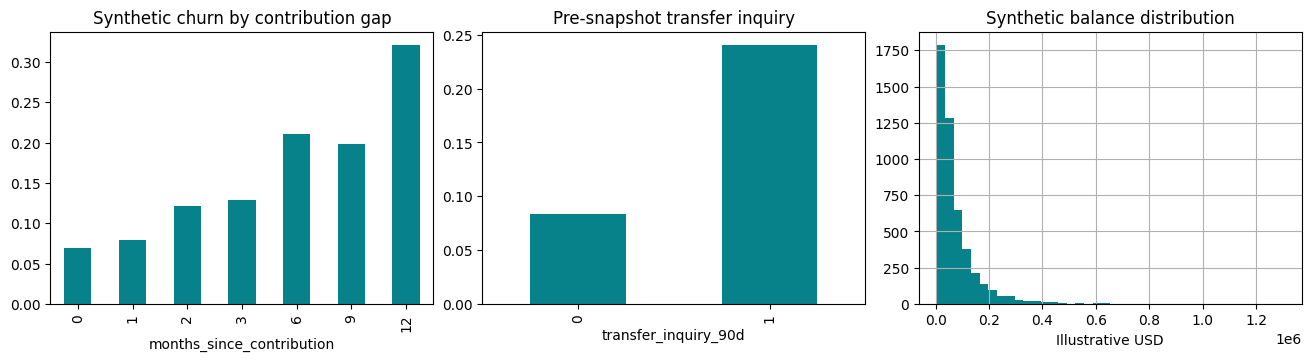

In [2]:
fit=d[pd.to_datetime(d.snapshot_date)<='2023-12-31']
display(fit.isna().sum().to_frame('missing').query('missing > 0'))
display(fit[['account_balance','monthly_contribution','tenure_months']].describe())
fig,ax=plt.subplots(1,3,figsize=(13,3.5),layout='constrained')
fit.groupby('months_since_contribution').churn_90d.mean().plot.bar(ax=ax[0],color='#07828b',title='Synthetic churn by contribution gap')
fit.groupby('transfer_inquiry_90d').churn_90d.mean().plot.bar(ax=ax[1],color='#07828b',title='Pre-snapshot transfer inquiry')
fit.account_balance.hist(bins=40,ax=ax[2],color='#07828b');ax[2].set(title='Synthetic balance distribution',xlabel='Illustrative USD')
plt.show()

## 3. Temporal validation and probability calibration
Base fit: Jan–Dec 2023; internal embargo: Jan–Mar 2024; calibration: Apr–Jun 2024; embargo: Jul–Sep 2024; validation: Oct 2024–Mar 2025; embargo: Apr–Jun 2025; test: Jul–Dec 2025. All 90-day outcomes mature before the next stage. Frozen base models are sigmoid calibrated on later training records. Validation Brier selects the model and validation F2 selects the flag threshold. Test results are evaluated once with the final specification.

In [3]:
m=main()
display(pd.read_csv('outputs/validation_metrics.csv'))
print('Final test metrics:')
display(pd.Series({k:m[k] for k in ['roc_auc','auc_ci95','average_precision','brier','precision','recall','f2','threshold']}))
display(pd.read_csv('outputs/splits.csv').groupby('model_stage').size().to_frame('members'))

{
  "roc_auc": 0.7746746944644141,
  "average_precision": 0.33160119513054603,
  "brier": 0.0850769104369276,
  "precision": 0.22800495662949194,
  "recall": 0.7076923076923077,
  "f2": 0.49810503519220356,
  "auc_ci95": [
    0.7410566041069405,
    0.8041912471793393
  ],
  "winner": "logistic",
  "threshold": 0.1,
  "rows": 14400,
  "train_rows": 7200,
  "base_fit_rows": 4800,
  "calibration_rows": 1200,
  "internal_embargo_rows": 1200,
  "validation_rows": 2400,
  "test_rows": 2400,
  "embargo_rows": 2400,
  "test_churn_rate": 0.10833333333333334,
  "flagged_members": 807,
  "test_total_balance": 188507565.41,
  "flagged_balance_if_all_leave": 64625425.34,
  "expected_outflow_90d": 19294568.888719965,
  "expected_annual_fee_revenue_at_risk": 114992.1433978246,
  "observed_synthetic_outflow_90d": 19748855.369999997,
  "campaign": {
    "policy": "value",
    "contacts": 142,
    "expected_assets_retained": 1668897.2006283232,
    "expected_fee_revenue_preserved": 11023.414137466185,

,model,roc_auc,average_precision,brier,precision,recall,f2
0,prior,0.500000,0.107083,0.095622,0.0000,0.000000,0.000000
1,logistic,0.760059,0.350163,0.083463,0.4375,0.027237,0.033525
2,boosting,0.731474,0.307963,0.086555,0.5000,0.007782,0.009690


roc_auc                                              0.774675
auc_ci95             [0.7410566041069405, 0.8041912471793393]
average_precision                                    0.331601
brier                                                0.085077
precision                                            0.228005
recall                                               0.707692
f2                                                   0.498105
threshold                                                 0.1
dtype: object

,members
model_stage,
base_fit,4800
calibration,1200
embargo,2400
internal_embargo,1200
test,2400
validation,2400


## 4. Evidence and tradeoffs
ROC and average precision measure ranking; Brier and calibration inspect probability scale. F2 emphasizes recall, but false positives and missed leavers are reported. Bootstrap AUC uncertainty resamples test members for a fixed model. Feature importance reflects generated associations, not proven retention remedies.

Confusion matrix, actual rows / predicted columns [stay,leave]: [[1517, 623], [76, 184]]


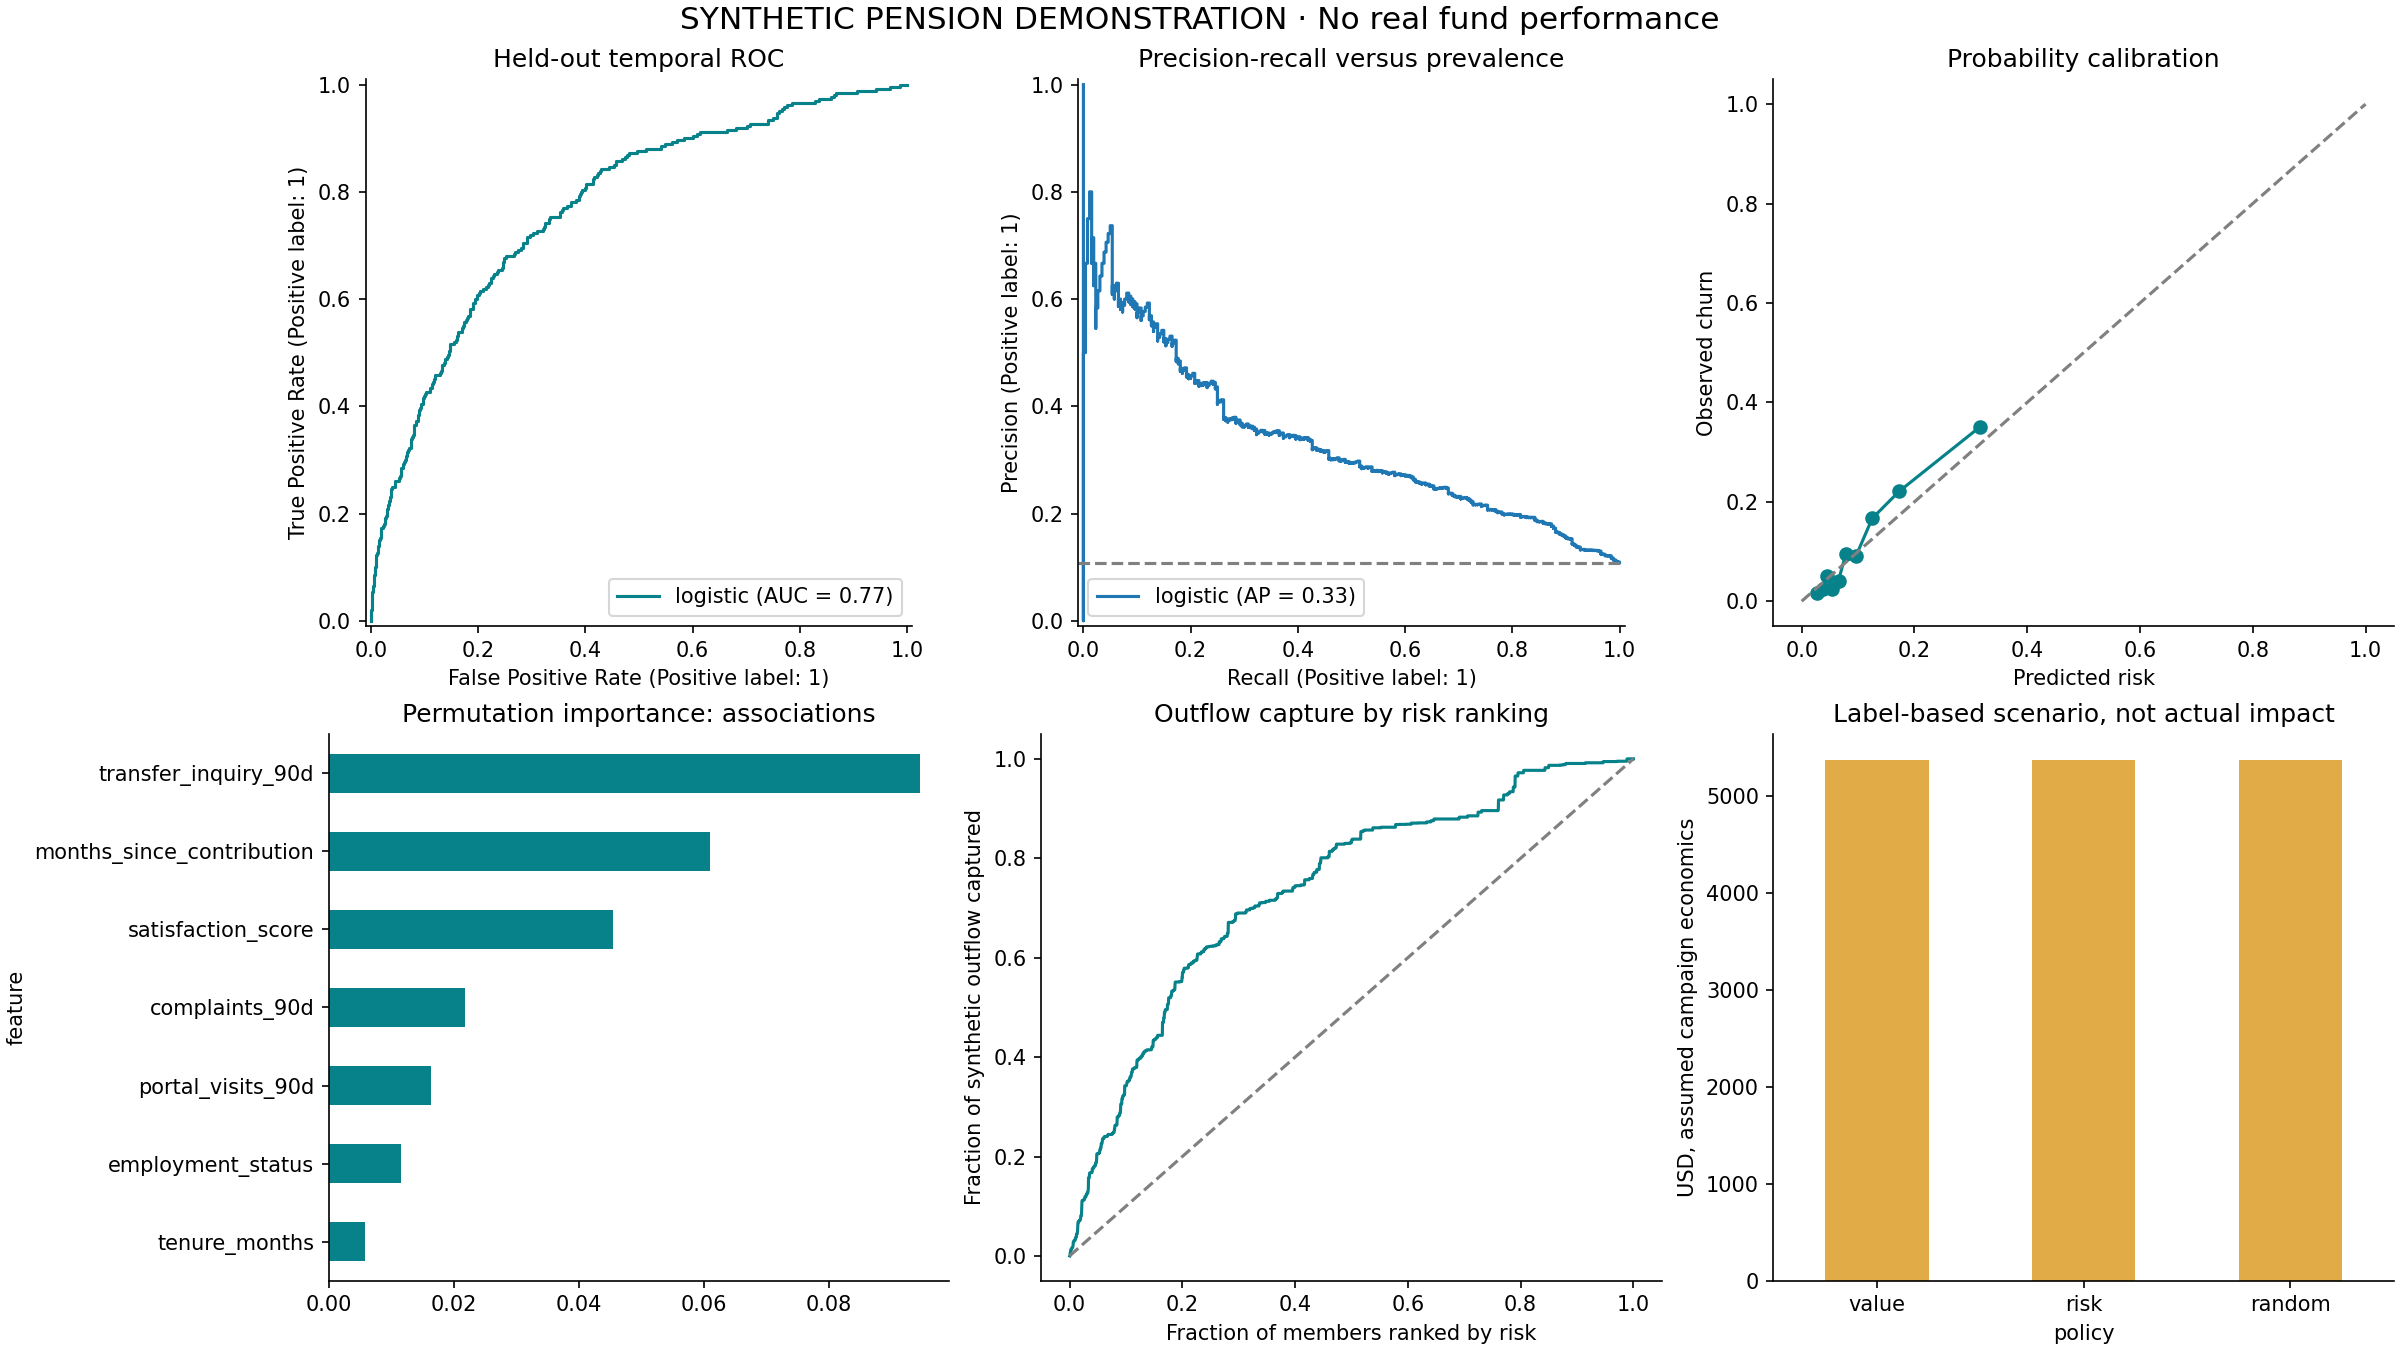

,feature,auc_drop,std
0,transfer_inquiry_90d,0.094590,0.006785
1,months_since_contribution,0.061093,0.010236
2,satisfaction_score,0.045421,0.002647
3,complaints_90d,0.021840,0.002535
4,portal_visits_90d,0.016406,0.001384
5,employment_status,0.011549,0.003279
6,tenure_months,0.005746,0.003373
7,account_balance,0.000546,0.000400
8,annual_fee_rate,-0.000551,0.001496
9,monthly_contribution,-0.000668,0.000297


,age_group,n,observed_churn,predicted_churn,brier,recall
0,25–35,757,0.096433,0.105183,0.077758,0.739726
1,46–60,980,0.117347,0.100695,0.090074,0.704348
2,36–45,663,0.108597,0.099777,0.086047,0.680556


In [4]:
display(Image(filename='outputs/evaluation.png'))
display(pd.read_csv('outputs/feature_importance.csv'))
display(pd.read_csv('outputs/subgroup_audit.csv'))
print('Confusion matrix, actual rows / predicted columns [stay,leave]:',m['confusion_matrix'])

## 5. Task 1 — List members who might leave
Each member has a probability and flag. The validation-selected threshold is not an assertion that departure is certain. Exporting the full prediction population also makes risk below the threshold visible.

In [5]:
scores=pd.read_csv('outputs/member_predictions.csv')
flagged=pd.read_csv('outputs/flagged_members.csv')
print('Flagged:',len(flagged),'of',len(scores))
display(flagged[['member_id','snapshot_date','churn_probability_90d','churn_flag','account_balance']].head(15))

Flagged: 807 of 2400


,member_id,snapshot_date,churn_probability_90d,churn_flag,account_balance
0,SYN-013381,2025-10-31,0.795112,True,19355.80
1,SYN-012831,2025-09-30,0.726366,True,23629.53
2,SYN-012165,2025-07-31,0.703967,True,105371.63
3,SYN-013471,2025-10-31,0.617505,True,16356.88
4,SYN-012404,2025-08-31,0.611701,True,95422.63
5,SYN-012062,2025-07-31,0.585205,True,34479.95
6,SYN-014085,2025-12-31,0.573318,True,19563.69
7,SYN-012342,2025-07-31,0.563424,True,54476.28
8,SYN-013449,2025-10-31,0.560416,True,50316.87
9,SYN-013405,2025-10-31,0.556645,True,79541.43


## 6. Task 2 — How much each member would take
Conditional amount = balance × transfer fraction (default 100%). Expected 90-day outflow = probability × conditional amount. Annualized fee exposure = expected outflow × annual fee rate. Fees are the administrator’s revenue; member account balances are not. Totals pool six snapshot cohorts, not one current fund roster.

In [6]:
display(flagged[['member_id','churn_probability_90d','amount_if_member_leaves','expected_outflow_90d','expected_annual_fee_revenue_at_risk']].head(15))
print(f'If every flagged member leaves: ${flagged.amount_if_member_leaves.sum():,.2f}')
print(f'Expected 90-day outflow, all test members: ${scores.expected_outflow_90d.sum():,.2f}')
print(f'Expected annualized fee exposure: ${scores.expected_annual_fee_revenue_at_risk.sum():,.2f}')
print(f'Observed synthetic full-transfer outflow: ${scores.actual_outflow_90d.sum():,.2f}')

If every flagged member leaves: $64,625,425.34
Expected 90-day outflow, all test members: $19,294,568.89
Expected annualized fee exposure: $114,992.14
Observed synthetic full-transfer outflow: $19,748,855.37


,member_id,churn_probability_90d,amount_if_member_leaves,expected_outflow_90d,expected_annual_fee_revenue_at_risk
0,SYN-013381,0.795112,19355.80,15390.036777,115.425276
1,SYN-012831,0.726366,23629.53,17163.678312,51.491035
2,SYN-012165,0.703967,105371.63,74178.176461,741.781765
3,SYN-013471,0.617505,16356.88,10100.449216,101.004492
4,SYN-012404,0.611701,95422.63,58370.114399,583.701144
5,SYN-012062,0.585205,34479.95,20177.823558,151.333677
6,SYN-014085,0.573318,19563.69,11216.207274,84.121555
7,SYN-012342,0.563424,54476.28,30693.265291,153.466326
8,SYN-013449,0.560416,50316.87,28198.380355,211.487853
9,SYN-013405,0.556645,79541.43,44276.314374,332.072358


## 7. Retention investment scenario
Default: save 25% of otherwise leavers; preserve one year of fees at constant balance/rate; 70% margin; $25 all-in cost/contact; at most 200 contacts. Only flagged members with positive expected net contribution are eligible. Contact capacity is a ceiling. No treatment outcomes exist: these are assumptions, not actual savings.

In [7]:
q=campaign(scores)
print('Contacts:',len(q))
print(f'Expected member assets retained: ${q.expected_assets_retained.sum():,.2f}')
print(f'Expected fee revenue preserved: ${q.expected_fee_revenue_preserved.sum():,.2f}')
print(f'Expected net contribution: ${q.expected_net_contribution.sum():,.2f}')
display(q.head(10))
display(pd.read_csv('outputs/policy_comparison.csv'))
# Default 200 cap includes all 142 positive-value flags, so policies tie.
# A 50-contact cap makes prioritization consequential.
rows=[]
for policy in ['value','risk','random']:
    c=campaign(scores,capacity=50,strategy=policy)
    rows.append({'policy':policy,'contacts':len(c),'expected_net':c.expected_net_contribution.sum()})
display(pd.DataFrame(rows))
s=pd.read_csv('outputs/sensitivity.csv')
display(s.pivot(index='save_rate',columns='cost',values='expected_net_contribution'))

Contacts: 142
Expected member assets retained: $1,668,897.20
Expected fee revenue preserved: $11,023.41
Expected net contribution: $4,166.39


,member_id,snapshot_date,account_balance,annual_fee_rate,churn_probability_90d,churn_flag,amount_if_member_leaves,expected_outflow_90d,annual_fee_revenue_if_member_leaves,expected_annual_fee_revenue_at_risk,actual_churn_90d,actual_outflow_90d,expected_assets_retained,expected_fee_revenue_preserved,expected_net_contribution
895,SYN-012896,2025-09-30,726197.79,0.0075,0.267805,True,726197.79,194479.537650,5446.483425,1458.596532,0,0.00,48619.884412,364.649133,230.254393
1352,SYN-013353,2025-10-31,673930.27,0.0075,0.230710,True,673930.27,155482.628595,5054.477025,1166.119714,0,0.00,38870.657149,291.529929,179.070950
1698,SYN-013699,2025-11-30,1217314.86,0.0075,0.122464,True,1217314.86,149077.736434,9129.861450,1118.083023,0,0.00,37269.434108,279.520756,170.664529
592,SYN-012593,2025-08-31,677625.71,0.0050,0.279521,True,677625.71,189410.313348,3388.128550,947.051567,0,0.00,47352.578337,236.762892,140.734024
1058,SYN-013059,2025-09-30,725374.28,0.0050,0.260752,True,725374.28,189142.977214,3626.871400,945.714886,0,0.00,47285.744303,236.428722,140.500105
1604,SYN-013605,2025-11-30,242956.27,0.0100,0.381651,True,242956.27,92724.485488,2429.562700,927.244855,1,242956.27,23181.121372,231.811214,137.267850
848,SYN-012849,2025-09-30,802905.26,0.0050,0.186910,True,802905.26,150070.865058,4014.526300,750.354325,0,0.00,37517.716264,187.588581,106.312007
1433,SYN-013434,2025-10-31,342174.56,0.0100,0.219041,True,342174.56,74950.123444,3421.745600,749.501234,0,0.00,18737.530861,187.375309,106.162716
164,SYN-012165,2025-07-31,105371.63,0.0100,0.703967,True,105371.63,74178.176461,1053.716300,741.781765,1,105371.63,18544.544115,185.445441,104.811809
2012,SYN-014013,2025-12-31,122971.40,0.0100,0.494680,True,122971.40,60831.451605,1229.714000,608.314516,0,0.00,15207.862901,152.078629,81.455040


,policy,contacts,expected_assets_retained,expected_fee_revenue_preserved,expected_net_contribution,label_based_scenario_net
0,value,142,1.668897e+06,11023.414137,4166.389896,5369.333132
1,risk,142,1.668897e+06,11023.414137,4166.389896,5369.333132
2,random,142,1.668897e+06,11023.414137,4166.389896,5369.333132


,policy,contacts,expected_net
0,value,50,3289.255443
1,risk,50,2021.570322
2,random,50,1318.350801


cost,10,25,50,100
save_rate,,,,
0.10,1666.555958,600.112258,166.311353,2.101757
0.20,5150.065444,2725.161724,1200.224516,332.622706
0.25,6937.581805,4166.389896,2041.846569,655.218623
0.30,8725.098166,5780.337683,3055.114169,1146.756533
0.40,12300.130888,9300.130888,5450.323447,2400.449033


## 8. Score unseen member snapshots
The input example contains no churn or actual-outflow target fields. It demonstrates the schema, not external validation. IDs must be unique, amounts finite/nonnegative, categories recognized and annual fees entered as decimals. The trusted saved pipeline handles preprocessing. Never load untrusted serialized models.

In [8]:
from src.score import score_frame
example=pd.read_csv('data/example_members.csv')
assert not {'churn_90d','actual_outflow_90d'} & set(example.columns)
display(score_frame(example).head())

,member_id,snapshot_date,account_balance,annual_fee_rate,churn_probability_90d,churn_flag,amount_if_member_leaves,expected_outflow_90d,annual_fee_revenue_if_member_leaves,expected_annual_fee_revenue_at_risk
0,SYN-014381,2025-12-31,82258.96,0.0075,0.107830,True,82258.96,8869.957150,616.942200,66.524679
1,SYN-014382,2025-12-31,24411.01,0.0075,0.059526,False,24411.01,1453.090559,183.082575,10.898179
2,SYN-014383,2025-12-31,24718.13,0.0050,0.039447,False,24718.13,975.064752,123.590650,4.875324
3,SYN-014384,2025-12-31,149701.41,0.0050,0.032243,False,149701.41,4826.783160,748.507050,24.133916
4,SYN-014385,2025-12-31,38132.25,0.0050,0.245698,True,38132.25,9369.003727,190.661250,46.845019


## 9. Interpretation and next steps
The project completes the two requested analytical tasks. It cannot prove that outreach stops departures. Synthetic labels reflect designed relationships; reported performance does not generalize to real pension members. The precision/recall tradeoff creates many false flags.

To validate retention, acquire authorized de-identified fund snapshots, define transferable balances and voluntary exits, verify pre-snapshot feature lineage, evaluate untouched temporal data and randomize outreach versus control. Measure incremental 90-day transfers and later retained fee contribution with uncertainty. Monitor calibration, drift, subgroup errors and contact costs. Respect members’ transfer choices.

See `README.md`, `MODEL_CARD.md`, `DATA_DICTIONARY.md` and `GITHUB_GUIDE.md` for full definitions and reproduction instructions.